### Highly Composite, Highly Divisible, and Superabundant Numbers

This notebook explores several ways to operationalize our intuition about what it means for a number like 1260 to have "lots" of divisors. It starts with an *ad hoc* definition about the percentage of numbers between 1 and 20 which divide it (not too far from Plato's discussion of 5040) and proceeds to two definitions involving the divisor function $\sigma_z(n)$: highly composite numbers and superabundant numbers. The numbers 1260 and 5040 share the infinitely rare property of being both highly composite and highly abundant; I say "infinitely rare" because there are only a finite number of numbers with both properties; [449 of them](https://oeis.org/A166981), in fact. The notebooks explores the combinatorics of the largest of these via generating polynomials at the end.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from textwrap import wrap
from functools import reduce

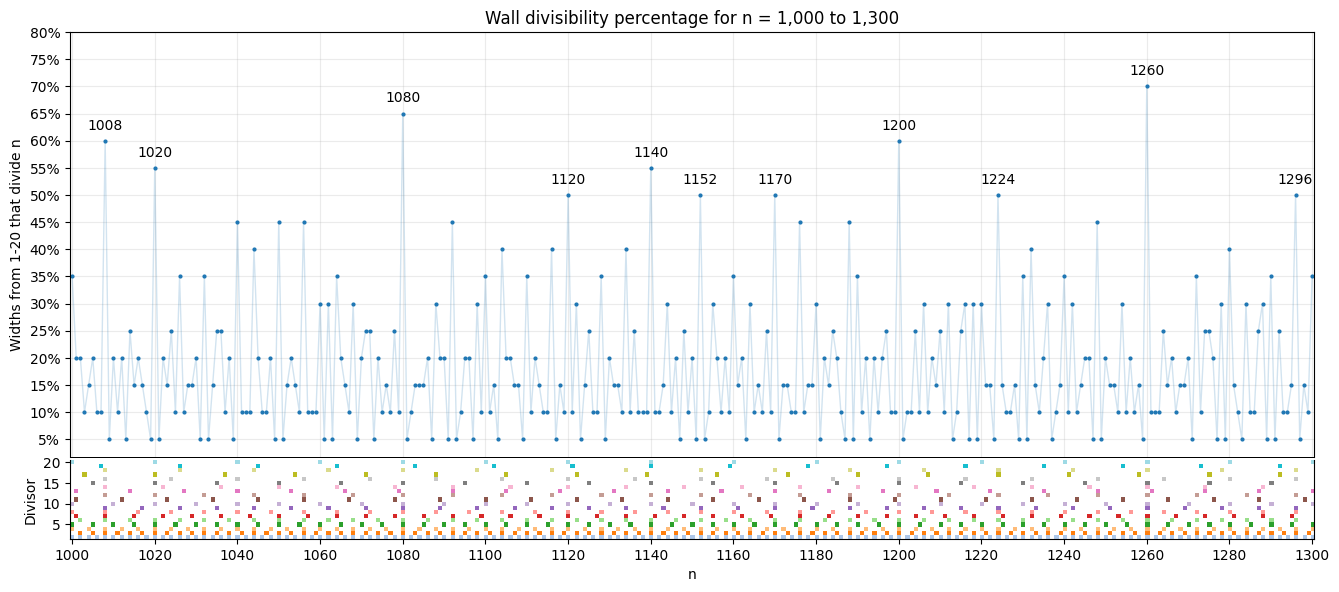

In [2]:
DIVISOR_RANGE = 20
MIN_N = 1_000
MAX_N = 1_300

n_values = range(MIN_N, MAX_N + 1)

percentages = [
    100
    * (1 + sum(n % divisor == 0 for divisor in range(2, DIVISOR_RANGE + 1)))
    / DIVISOR_RANGE
    for n in n_values
]

fig, (ax, heatmap_ax) = plt.subplots(
    2,
    1,
    figsize=(13.5, 6),
    sharex=True,
    gridspec_kw={"height_ratios": (5, 1), "hspace": 0},
)
ax.plot(n_values, percentages, linewidth=1, alpha=0.2, color="C0")
ax.plot(
    n_values,
    percentages,
    linestyle="none",
    marker=".",
    markersize=4,
    color="C0",
)

ax.set(
    title=f"Wall divisibility percentage for n = {MIN_N:,} to {MAX_N:,}",
    ylabel="Widths from 1-20 that divide n",
)
ax.set_yticks(range(5, 81, 5))
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0f}%")
ax.tick_params(axis="x", which="both", bottom=False, labelbottom=False)
for n, percentage in zip(n_values, percentages, strict=True):
    if percentage >= 50:
        ax.annotate(
            str(n),
            (n, percentage),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center",
            va="bottom",
        )
ax.grid(alpha=0.25)
ax.spines["bottom"].set_linewidth(0.72)

tab20 = plt.colormaps["tab20"].colors
heatmap = np.zeros((DIVISOR_RANGE - 1, len(n_values), 4))
for divisor in range(2, DIVISOR_RANGE + 1):
    divides = [n % divisor == 0 for n in n_values]
    heatmap[divisor - 2, divides] = (*tab20[divisor - 1], 1)
heatmap_ax.imshow(
    heatmap,
    origin="lower",
    interpolation="none",
    aspect="equal",
    extent=(MIN_N - 0.5, MAX_N + 0.5, 1.5, DIVISOR_RANGE + 0.5),
)
heatmap_ax.set(
    xlabel="n",
    ylabel="Divisor",
    ylim=(1.5, DIVISOR_RANGE + 0.5),
)
heatmap_ax.set_xticks(range(MIN_N, MAX_N + 1, 20))
heatmap_ax.set_yticks([5, 10, 15, 20])
heatmap_ax.spines["top"].set_visible(False)

fig.tight_layout()
plt.show()

In [3]:
def prime_factors(n: int) -> list[int]:
    if not isinstance(n, int) or n <= 1:
        raise ValueError("Requires an integer of 2 or more.")
    prime_factors = []

    for factor in (2, 3):
        while n % factor == 0:
            prime_factors.append(factor)
            n //= factor

    factor = 5
    stride = 2
    while factor * factor <= n:
        if n % factor == 0:
            prime_factors.append(factor)
            n //= factor
        else:
            factor += stride
            stride = 6 - stride # 2, 4, 2, ...

    if n > 1:
        prime_factors.append(n)

    return prime_factors

In [4]:
from math import prod

for n in range(2, 10_000):
    factors = prime_factors(n)
    assert prod(factors) == n, f"{n}: {factors}"
    for factor in factors:
        assert len(prime_factors(factor)) == 1

In [5]:
prime_factors(1260)

[2, 2, 3, 3, 5, 7]

In [6]:
def sigma(n, z=1):
    "divisor function sigma_z(n)."
    total = 0
    for d in range(1, n+1):
        if n % d == 0:
            total += d ** z
    return total

assert sigma(6) == 12
assert sigma(1260, 0) == 36

for n in range(3, 1000):
    if len(prime_factors(n)) == 1:
        assert sigma(n) == n + 1
        assert sigma(n, z=0) == 2

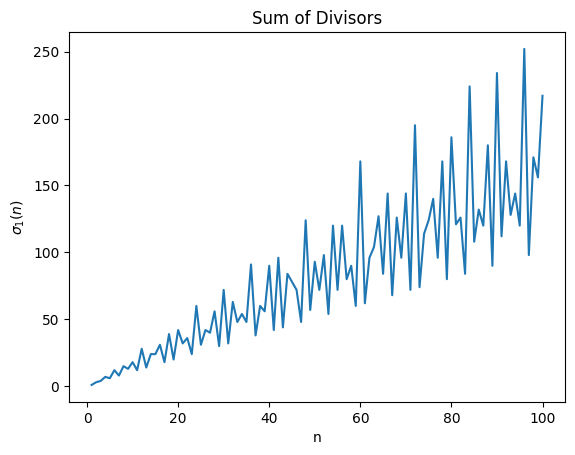

In [7]:

N = 100
ns = list(range(1, N+1))
sigmas = [ sigma(n) for n in ns ]
plt.plot(ns, sigmas)
plt.title("Sum of Divisors")
plt.xlabel("n")
plt.ylabel(r"$\sigma_1(n)$");


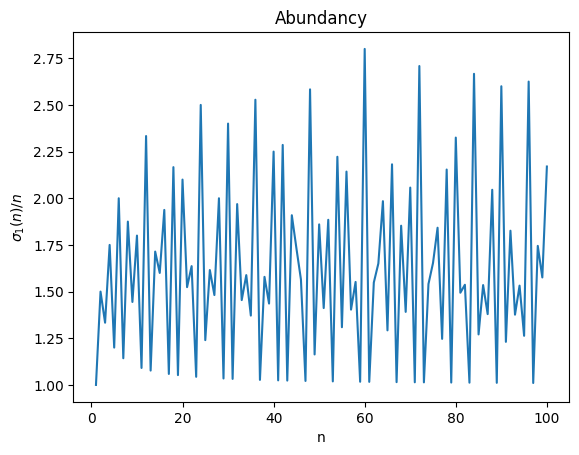

In [8]:
N = 100
ns = list(range(1, N+1))
abundances = [ sigma(n)/n for n in ns ]
plt.plot(ns, abundances)
plt.title("Abundancy")
plt.xlabel("n")
plt.ylabel(r"$\sigma_1(n)/n$");

In [9]:
N = 10_000
superabundant_numbers = []
superabundances = []
last_superabundance = 0
for n in range(1, N+1):
    abuncance = sigma(n)/n
    if abuncance > last_superabundance:
        last_superabundance = abuncance
        superabundant_numbers.append(n)
        superabundances.append(abuncance)

In [10]:
# up to 100,000. Takes about 5 minutes to calculate with the brute force algorithm above.
more_superabundant_numbers = [
    1,
    2,
    4,
    6,

    12,
    24,
    36,
    48,
    60,
    
    120,
    180,
    240,
    360,
    720,
    840,

    1260,
    1680,
    2520,
    5040,

    10080,
    15120,
    25200,
    27720,
    55440,
]

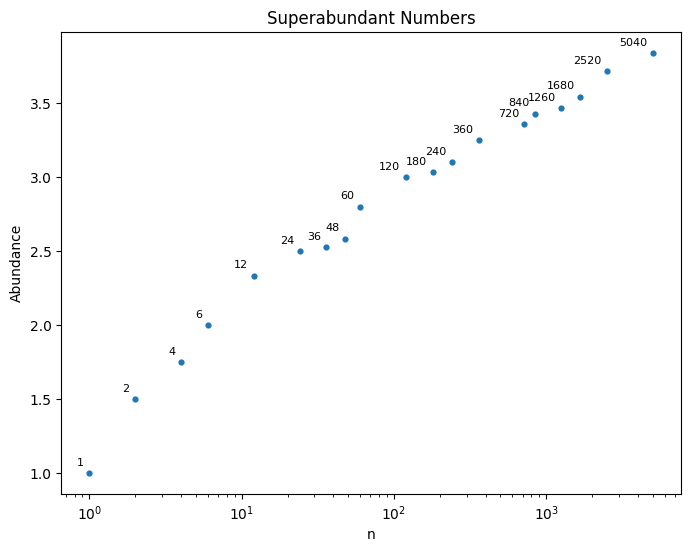

In [11]:
plt.figure(figsize=(8, 6))
plt.scatter(superabundant_numbers, superabundances, s=12)

for number, abundance in zip(superabundant_numbers, superabundances):
    plt.annotate(
        str(number),
        (number, abundance),
        xytext=(-4, 4),
        textcoords="offset points",
        ha="right",
        va="bottom",
        fontsize=8,
    )

plt.title("Superabundant Numbers")
plt.ylabel("Abundance")
plt.xlabel("n")
plt.xscale("log")

In [12]:
for n in superabundant_numbers[1:]:
    factor_list = ", ".join(str(p) for p in prime_factors(n))
    print(f"{n:>10}: {factor_list}")

         2: 2
         4: 2, 2
         6: 2, 3
        12: 2, 2, 3
        24: 2, 2, 2, 3
        36: 2, 2, 3, 3
        48: 2, 2, 2, 2, 3
        60: 2, 2, 3, 5
       120: 2, 2, 2, 3, 5
       180: 2, 2, 3, 3, 5
       240: 2, 2, 2, 2, 3, 5
       360: 2, 2, 2, 3, 3, 5
       720: 2, 2, 2, 2, 3, 3, 5
       840: 2, 2, 2, 3, 5, 7
      1260: 2, 2, 3, 3, 5, 7
      1680: 2, 2, 2, 2, 3, 5, 7
      2520: 2, 2, 2, 3, 3, 5, 7
      5040: 2, 2, 2, 2, 3, 3, 5, 7


In [13]:
highly_composite_numbers = []
highly_composite_divisors = []
max_divisors = 0
for n in range(1, N+1):
    n_divisors = sigma(n, 0)
    if n_divisors > max_divisors:
        highly_composite_numbers.append(n)
        highly_composite_divisors.append(n_divisors)
        max_divisors = n_divisors

print(highly_composite_numbers)

[1, 2, 4, 6, 12, 24, 36, 48, 60, 120, 180, 240, 360, 720, 840, 1260, 1680, 2520, 5040, 7560]


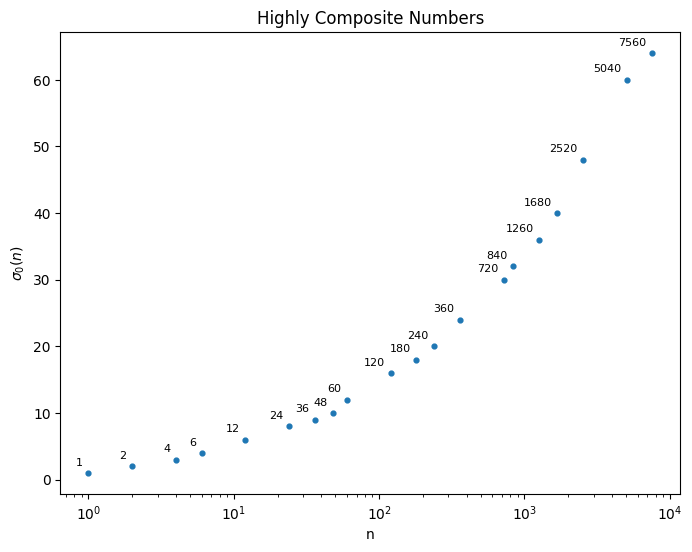

In [14]:
plt.figure(figsize=(8, 6))
plt.scatter(highly_composite_numbers, highly_composite_divisors, s=12)

for number, n_divisors in zip(highly_composite_numbers, highly_composite_divisors):
    plt.annotate(
        str(number),
        (number, n_divisors),
        xytext=(-4, 4),
        textcoords="offset points",
        ha="right",
        va="bottom",
        fontsize=8,
    )

plt.title("Highly Composite Numbers")
plt.ylabel(r"$\sigma_0(n)$")
plt.xlabel("n")
plt.xscale("log")

In [15]:
for n in highly_composite_numbers[1:]:
    factor_list = ", ".join(str(p) for p in prime_factors(n))
    print(f"{n:>10}: {factor_list}")

         2: 2
         4: 2, 2
         6: 2, 3
        12: 2, 2, 3
        24: 2, 2, 2, 3
        36: 2, 2, 3, 3
        48: 2, 2, 2, 2, 3
        60: 2, 2, 3, 5
       120: 2, 2, 2, 3, 5
       180: 2, 2, 3, 3, 5
       240: 2, 2, 2, 2, 3, 5
       360: 2, 2, 2, 3, 3, 5
       720: 2, 2, 2, 2, 3, 3, 5
       840: 2, 2, 2, 3, 5, 7
      1260: 2, 2, 3, 3, 5, 7
      1680: 2, 2, 2, 2, 3, 5, 7
      2520: 2, 2, 2, 3, 3, 5, 7
      5040: 2, 2, 2, 2, 3, 3, 5, 7
      7560: 2, 2, 2, 3, 3, 3, 5, 7


In [16]:
either = set(highly_composite_numbers) | set(superabundant_numbers)
both = set(highly_composite_numbers) & set(superabundant_numbers)
either - both

{7560}

In [17]:
first_only_superabundant = 1_163_962_800

In [18]:

largest_both = (
    2**10 * 3**6 * 5**4 * 7**3 * 11**3 * 13**2 * 17**2 * 19**2 * 23**2 * 29 * 31 * 37 *
    41 * 43 * 47 * 53 * 59 * 61 * 67 * 71 * 73 * 79 * 83 * 89 * 97 * 101 * 103 * 107 *
    109 * 113 * 127 * 131 * 137 * 139 * 149 * 151 * 157 * 163 * 167 * 173 * 179 *
    181 * 191 * 193 * 197 * 199 * 211 * 223 * 227 * 229 * 233 * 239 * 241 * 251 * 257 *
    263 * 269 * 271 * 277 * 281 * 283 * 293 * 307 * 311 * 313 * 317 * 331 * 337 * 347
)
largest_both


6673677805609568153080220113289093737608697348112335683143355114958436572669652057828038735276428369020778066916839412571610096354615871011364980958080000

In [19]:
def foil(p: list[int], q: list[int]) -> list[int]:
    """multiply polynomials."""
    r = [ 0 for _ in range(len(p) + len(q) - 1)]
    for i, p_i in enumerate(p):
        for j, q_j in enumerate(q):
            r[i+j] += p_i * q_j
    return r

def polynomial_power(p: list[int], n: int) -> list[int]:
    q = p.copy()
    for i in range(n-1):
        q = foil(p, q)
    return q

def format_polynomial(p: list[int], variable="x") -> str:
    terms = []
    first = True

    for i in range(len(p) -1, -1, -1):
        coefficient = p[i]

        if coefficient == 0:
            continue

        # sign
        if first:
            first = False
            if coefficient > 0:
                sign = ""
            else:
                sign = "-"
        elif coefficient > 0:
            sign = " + "
        else: # coefficient < 0
            sign = " - "

        # coefficient
        abs_coefficient = abs(coefficient)
        if abs_coefficient == 1:
            formatted_coefficient = "1" if i == 0 else ""
        else:
            formatted_coefficient = str(abs_coefficient)

        # exponent
        if i == 0:
            exponent = ""
        elif i == 1:
            exponent = str(variable)
        else:
            exponent = f"{variable}^{i}"

        term = f"{sign}{formatted_coefficient}{exponent}"

        terms.append(term)

    return "".join(terms)

assert format_polynomial([1, 2, 1]) == "x^2 + 2x + 1"
assert format_polynomial([0, 0, 0]) == ""
assert format_polynomial([-1, -2, -1]) == "-x^2 - 2x - 1"
assert format_polynomial([9, 0, 9, 0, 9]) == "9x^4 + 9x^2 + 9"

assert format_polynomial(foil([1, 1], [1, 1, 1])) == "x^3 + 2x^2 + 2x + 1"
assert format_polynomial(polynomial_power([1, 1], 5)) == "x^5 + 5x^4 + 10x^3 + 10x^2 + 5x + 1"

In [20]:
# generating polynomial for 1260
generating_polynomial = foil(
    polynomial_power([1, 1], 2),
    polynomial_power([1, 1, 1], 2),
)
print(format_polynomial(generating_polynomial))
print(sum(generating_polynomial))

x^6 + 4x^5 + 8x^4 + 10x^3 + 8x^2 + 4x + 1
36


Visualization of the above ranks (1, 4, 8, 10, 8, 4, 1) from the [4D viewer](https://www.oranlooney.com/demos/1260/). Each row corresponds to a specific value of $\Omega(d)$, which counts the total number of prime factors of the divisor $d$ (with multiplicity.) For example, $140 = 2^2 \cdot 5 \cdot 5$ so $\Omega(140) = 4$ so is two rows down from the top.

![Ranks for 1260](data/images/1260_ranks.png)

In [21]:
# generating polynomial for 5040
generating_polynomial = reduce(foil, [
    [1, 1],
    [1, 1],
    [1, 1, 1],
    [1, 1, 1, 1, 1],
])
print(format_polynomial(generating_polynomial))

print("\nDivisors:", sum(generating_polynomial))
print("Dimensions:", len(set(prime_factors(5040))))

x^8 + 4x^7 + 8x^6 + 11x^5 + 12x^4 + 11x^3 + 8x^2 + 4x + 1

Divisors: 60
Dimensions: 4


In [22]:
def multiplicities(factors: list[int]):
    if len(factors) == 0:
        return []

    exponents = []
    exponent = 1
    current_factor = factors[0]
    for index in range(1, len(factors)):
        factor = factors[index]
        if factor == current_factor:
            exponent += 1
        else:
            exponents.append(exponent)
            current_factor = factor
            exponent = 1

    exponents.append(exponent)

    return exponents

assert multiplicities([]) == []
assert multiplicities([2]) == [1]
assert multiplicities([2, 2, 1]) == [2, 1]
assert multiplicities([2, 2, 2, 2, 3, 3, 3, 5, 5, 7]) == [4, 3, 2, 1]

In [23]:
def factor_powers(factors: list[int]) -> list[tuple[int, int]]:
    """Return each distinct factor paired with its multiplicity."""
    powers: dict[int, int] = {}
    for factor in factors:
        powers[factor] = powers.get(factor, 0) + 1
    return list(powers.items())


assert factor_powers(prime_factors(360)) == [(2, 3), (3, 2), (5, 1)]

In [24]:
def number_report(number: int) -> None:
    """Print a divisor and prime-factor report for a number."""
    factors = prime_factors(number)

    factors_and_exponents = factor_powers(factors)

    factorization = " * ".join(
        str(factor) if exponent == 1 else f"{factor}^{exponent}"
        for factor, exponent in factors_and_exponents
    )
    maximum_rank = sum(exponent for _, exponent in factors_and_exponents)

    generating_polynomial = reduce(
        foil,
        ([1] * (exponent + 1) for _, exponent in factors_and_exponents),
    )
    divisor_count = sum(generating_polynomial)
    divisor_sum = sigma(number, 1)
    abundancy = divisor_sum / n

    # cross check
    assert divisor_count == sigma(number, 0)
    assert maximum_rank == len(generating_polynomial) - 1

    print(number)
    print("Prime Factors:", " * ".join(str(factor) for factor in factors))
    print("Factorization:", factorization)
    print(
        "\nGenerating Polynomial:\n"
        + "\n".join(wrap(format_polynomial(generating_polynomial), 180))
    )
    print("\nDivisors:", divisor_count)
    print("Distinct Prime Factors:", len(set(factors)))
    print("Divisors Sum:", sigma(number, 1))
    print(f"Abundancy: {abundancy:0.2f}")
    print("Maximum Rank:", maximum_rank)


number_report(55440)

55440
Prime Factors: 2 * 2 * 2 * 2 * 3 * 3 * 5 * 7 * 11
Factorization: 2^4 * 3^2 * 5 * 7 * 11

Generating Polynomial:
x^9 + 5x^8 + 12x^7 + 19x^6 + 23x^5 + 23x^4 + 19x^3 + 12x^2 + 5x + 1

Divisors: 120
Distinct Prime Factors: 5
Divisors Sum: 232128
Abundancy: 30.70
Maximum Rank: 9


In [25]:
# 41st highly composite number (largest listed in OEIS)
number_report(2162160)

2162160
Prime Factors: 2 * 2 * 2 * 2 * 3 * 3 * 3 * 5 * 7 * 11 * 13
Factorization: 2^4 * 3^3 * 5 * 7 * 11 * 13

Generating Polynomial:
x^11 + 6x^10 + 17x^9 + 32x^8 + 47x^7 + 57x^6 + 57x^5 + 47x^4 + 32x^3 + 17x^2 + 6x + 1

Divisors: 320
Distinct Prime Factors: 6
Divisors Sum: 9999360
Abundancy: 1322.67
Maximum Rank: 11


In [26]:
# the largest of the 449 numbers which are both highly-composite and superabundant is:
#  2^10 * 3^6 * 5^4 * 7^3 * 11^3 * 13^2 * 17^2 * 19^2 * 23^2 * 29 * 31 * 37*...*347
largest_both_multiplicities = [10, 6, 4, 3, 3, 2, 2, 2, 2] + [1] * 60
lb_chains = [ [1]*(m+1) for m in largest_both_multiplicities ]
lb_generating_polynomial = reduce(foil, lb_chains)

print("\n".join(wrap(format_polynomial(lb_generating_polynomial), 180)))
print("\nDivisors:", sum(lb_generating_polynomial))
print("Dimensions:", f"{len(largest_both_multiplicities):,}")

x^94 + 69x^93 + 2355x^92 + 53011x^91 + 885382x^90 + 11703605x^89 + 127546883x^88 + 1178762376x^87 + 9430978677x^86 + 66361530436x^85 + 415832628016x^84 + 2343955423194x^83 +
11984976773547x^82 + 55980414301742x^81 + 240300376440508x^80 + 952901966608044x^79 + 3506632551750956x^78 + 12023272740093466x^77 + 38547613747067723x^76 + 115933314162512294x^75
+ 328031482432356412x^74 + 875522546330398928x^73 + 2209611083179421165x^72 + 5284831788586637608x^71 + 12003638957586248507x^70 + 25941786042864269301x^69 +
53441440578542605666x^68 + 105120711678059640931x^67 + 197756681662639240923x^66 + 356347043017540313373x^65 + 615957181931112735453x^64 + 1022758415434764499728x^63 +
1633530170922140000314x^62 + 2512917148337186756278x^61 + 3727967528994795001538x^60 + 5339944269148799835218x^59 + 7394036747010035932920x^58 + 9908266715042742374910x^57 +
12863397597844850464962x^56 + 16195846948980882693456x^55 + 19795366938843133153310x^54 + 23508608687980107292868x^53 + 27148751198748206925492x^5

In [27]:
def sieve(limit=20) -> list[int]:
    sieve = [True] * (limit + 1)
    sieve[0] = sieve[1] = False

    for p in range(2, limit + 1):
        if sieve[p]:
            for multiple in range(2 * p, limit + 1, p):
                sieve[multiple] = False

    return [p for p in range(limit + 1) if sieve[p]]

primes = sieve(347)

In [28]:
assert largest_both == prod(
    p**m
    for p, m in zip(
        primes,
        largest_both_multiplicities
    )
)

In [ ]:
# takes 3-5 minutes to run!
number_report(first_only_superabundant)

1163962800
Prime Factors: 2 * 2 * 2 * 2 * 3 * 3 * 5 * 5 * 7 * 11 * 13 * 17 * 19
Factorization: 2^4 * 3^2 * 5^2 * 7 * 11 * 13 * 17 * 19

Generating Polynomial:
x^13 + 8x^12 + 31x^11 + 78x^10 + 144x^9 + 209x^8 + 249x^7 + 249x^6 + 209x^5 + 144x^4 + 78x^3 + 31x^2 + 8x + 1

Divisors: 1440
Distinct Prime Factors: 8
Divisors Sum: 6044613120
Abundancy: 17419634.35
Maximum Rank: 13
